# Titanic: Exploring Passenger Survival

**Exploratory data analysis with Python**  
Tinashe Sean Mungoshi

Were younger passengers more likely to survive the Titanic disaster than older passengers? This project explores that question using passenger records, summary statistics and visualisations. It also looks at sex, passenger class and fares to put the age findings into context.

The focus is on understanding patterns in this dataset. This notebook does not build a prediction model or establish what caused those patterns.

## Project overview

The dataset contains **891 passenger records and 12 original columns**. Each row describes a passenger, including their recorded age, sex, ticket class, fare and survival status.

### Questions explored

- What does the passenger population look like, and where is information missing?
- How do fares and survival differ across passenger classes and sexes?
- How do the ages of survivors and non-survivors compare?
- Does survival vary across age groups?

### Notebook guide

1. Set up the analysis
2. Load the passenger data
3. Inspect the dataset
4. Check missing values
5. Explore passenger distributions
6. Compare fares and survival
7. Investigate age and survival
8. Discuss findings and limitations

### Running this notebook

Use Jupyter Notebook, JupyterLab or VS Code with a Python kernel. Install `pandas`, `numpy`, `matplotlib` and `seaborn` in that environment, then run the cells from top to bottom. The plotting code uses Seaborn's `errorbar` argument, so use Seaborn 0.12 or later.

The loading cell reads `titanic.csv` from a pinned commit in my `Projects` GitHub repository, so an internet connection is required. The attached CSV is a local reference copy; the code does not read it automatically.

### Reading the variables

| Column | Meaning |
| --- | --- |
| `Survived` | Survival outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ticket class: 1 = first, 2 = second, 3 = third |
| `Sex`, `Age` | Recorded sex and age in years |
| `SibSp` | Number of siblings or spouses aboard |
| `Parch` | Number of parents or children aboard |
| `Fare` | Recorded passenger fare |
| `Embarked` | Embarkation port code: C = Cherbourg, Q = Queenstown, S = Southampton |
| `PassengerId`, `Name`, `Ticket`, `Cabin` | Passenger identifier, name, ticket and cabin details |

The results describe these 891 records, rather than every person aboard the ship.

## 1. Set up the analysis

Import the libraries and set a consistent plotting style.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(
    {'figure.figsize': (6, 4)},
    style='ticks',
    color_codes=True,
    font_scale=0.8
)
%config InlineBackend.figure_formats = set(('retina', 'svg'))

import warnings
warnings.filterwarnings('ignore')

## 2. Load the passenger data

Read the CSV and preview the first ten rows to see how the passenger records are organised.

In [2]:
path = "https://github.com/tinashemungoshi/Projects/blob/8bf116b697f410f240e9a44b827a606cc2d31fa6/Titanic/titanic.csv"

data = pd.read_csv(path)

In [3]:
data.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


## 3. Inspect the dataset

Check the column types, numerical summaries, dimensions and column names before exploring relationships.

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
data.shape

(891, 12)

In [7]:
data.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Cabin',
 'Embarked']

## 4. Check missing values

Age, cabin and embarkation details contain missing entries. The next cells inspect the available cabin records and calculate the percentage missing in each column.

A separate `data_clean` table drops rows with missing age or embarkation details. The later analysis continues to use `data`, so this step does not remove those passengers from the main dataset. Age summaries and age-based plots use the available ages.

In [8]:
cabin = data['Cabin'].dropna()
cabin.head(10)

,Cabin
1,C85
3,C123
6,E46
10,G6
11,C103
21,D56
23,A6
27,C23 C25 C27
31,B78
52,D33


In [9]:
round(data.isnull().mean()*100, 2)

,0
PassengerId,0.00
Survived,0.00
Pclass,0.00
Name,0.00
Sex,0.00
Age,19.87
SibSp,0.00
Parch,0.00
Ticket,0.00
Fare,0.00


In [10]:
missing_values = ['Age', 'Cabin', 'Embarked']
missing_data = data[missing_values].isnull().mean()*100
print(round(missing_data, 2))


Age         19.87
Cabin       77.10
Embarked     0.22
dtype: float64


In [11]:
data['Age'].count()


np.int64(714)

In [12]:
data_clean = data.dropna(subset=['Age', 'Embarked'], axis=0)
data_clean['Age'].isnull().sum()

np.int64(0)

## 5. Explore passenger distributions

Start with age, sex, class and fare to understand who is represented in the dataset. The first frequency table counts combinations of four fields, rather than each field separately.

The `help()` cell is a retained reference for the plotting function.

In [13]:
data[['Pclass', 'Sex', 'Age', 'Fare']].value_counts()

Pclass  Sex     Age   Fare   
2       male    23.0  13.0000    3
                30.0  13.0000    3
                34.0  13.0000    3
3       male    22.0  7.2500     3
                17.0  8.6625     3
                                ..
2       female  30.0  13.0000    1
                      21.0000    1
                31.0  26.2500    1
                32.0  13.0000    1
                27.0  21.0000    1
Name: count, Length: 659, dtype: int64

In [14]:
help(sns.boxplot)

Help on function boxplot in module seaborn.categorical:

boxplot(
    data=None,
    *,
    x=None,
    y=None,
    hue=None,
    order=None,
    hue_order=None,
    orient=None,
    color=None,
    palette=None,
    saturation=0.75,
    fill=True,
    dodge='auto',
    width=0.8,
    gap=0,
    whis=1.5,
    linecolor='auto',
    linewidth=None,
    fliersize=None,
    hue_norm=None,
    native_scale=False,
    log_scale=None,
    formatter=None,
    legend='auto',
    ax=None,
    **kwargs
)
    Draw a box plot to show distributions with respect to categories.

    A box plot (or box-and-whisker plot) shows the distribution of quantitative
    data in a way that facilitates comparisons between variables or across
    levels of a categorical variable. The box shows the quartiles of the
    dataset while the whiskers extend to show the rest of the distribution,
    except for points that are determined to be "outliers" using a method
    that is a function of the inter-quartile range.


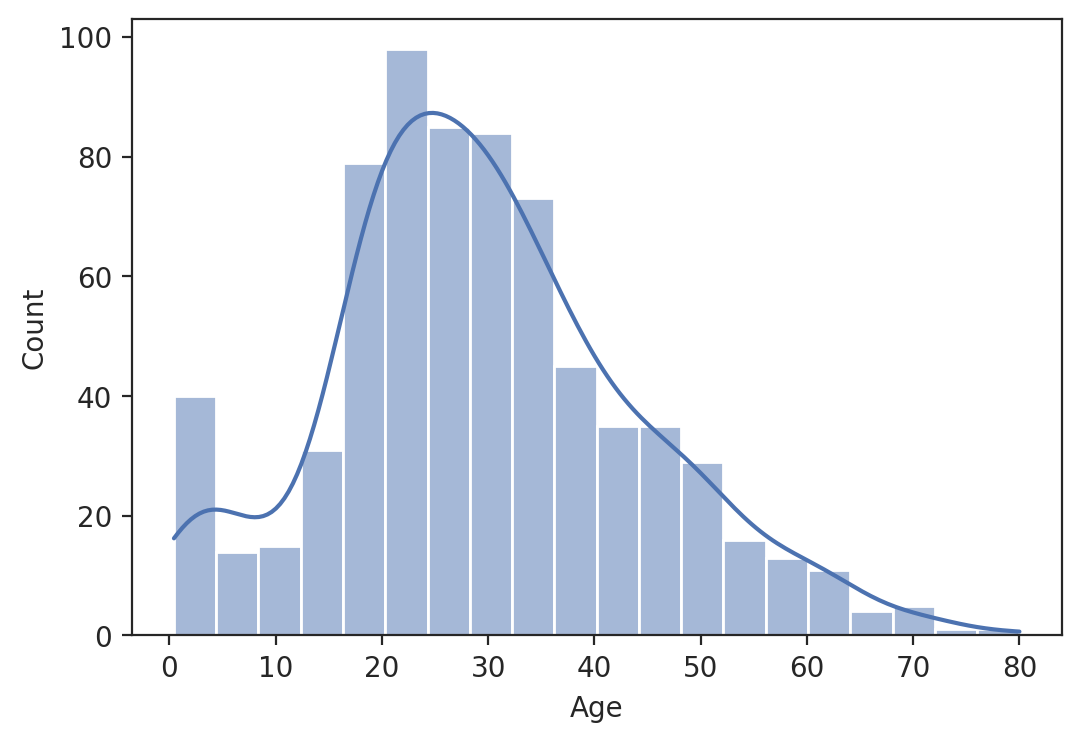

In [15]:
sns.histplot(data=data, x='Age', kde=True)
plt.show()

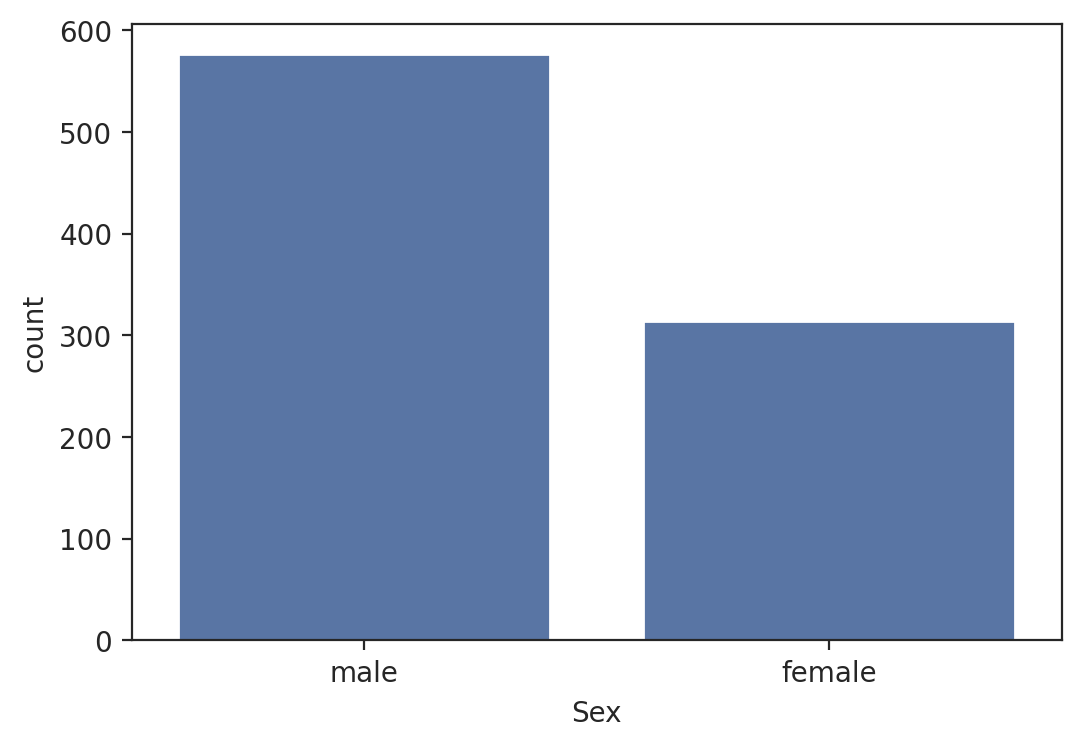

In [16]:
sns.countplot(data=data, x='Sex')
plt.show()

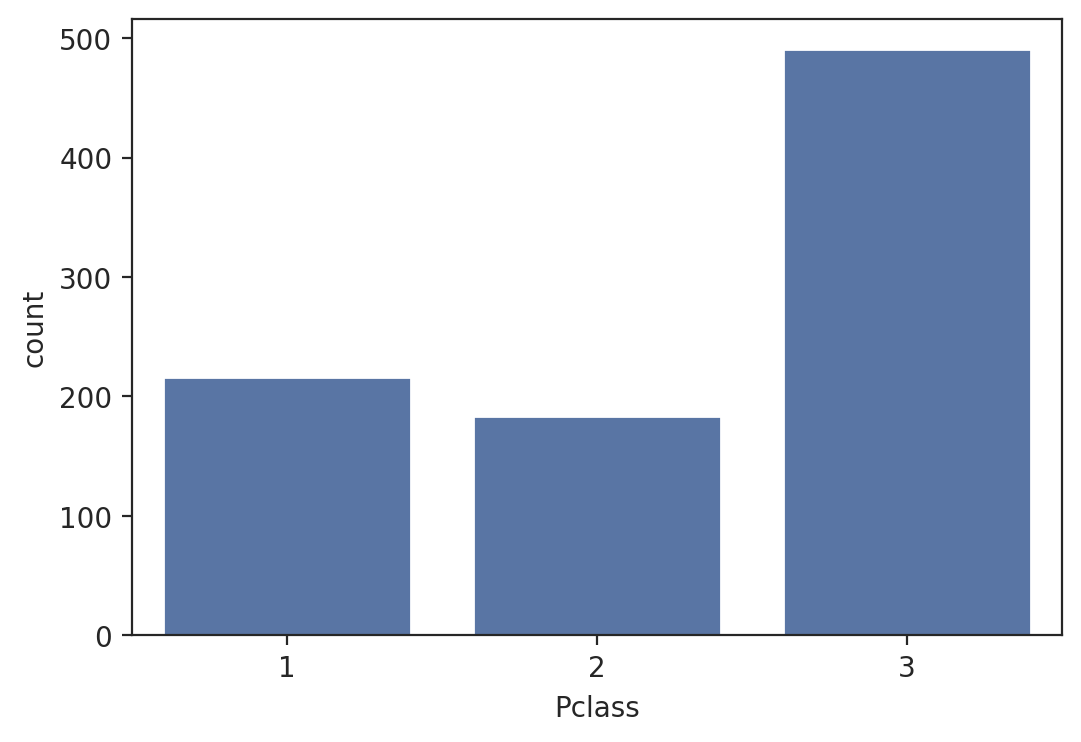

In [17]:
sns.countplot(data=data, x='Pclass')
plt.show()

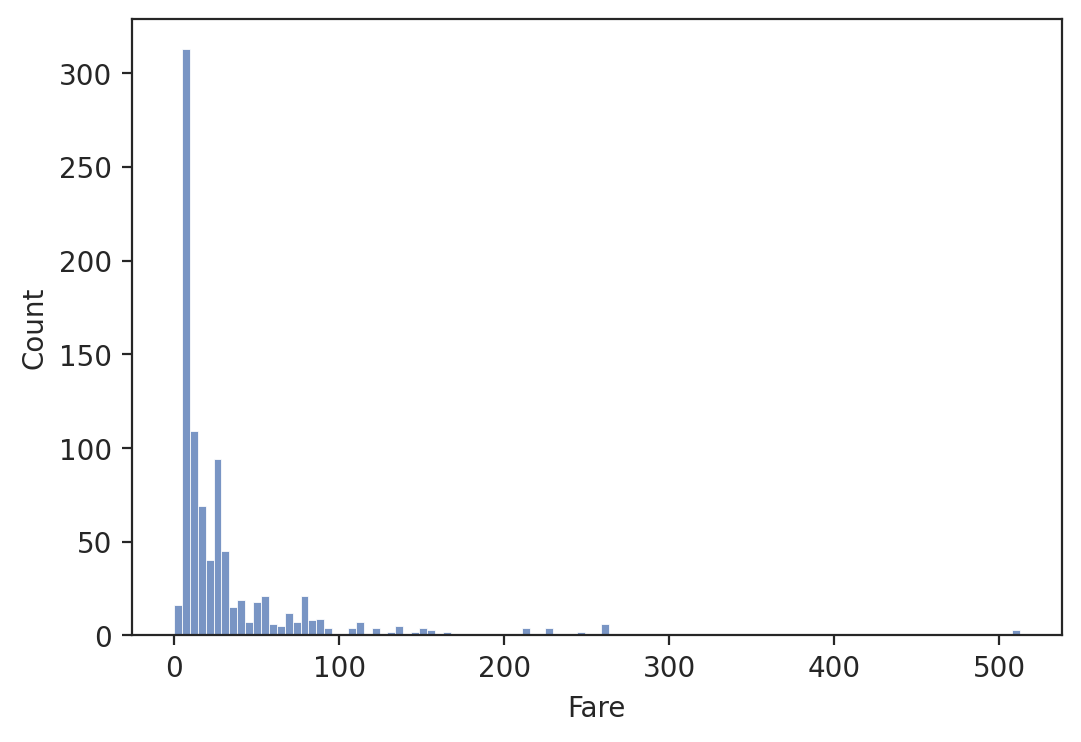

In [18]:
sns.histplot(data=data, x='Fare')
plt.show()

## 6. Compare fares and survival

Explore how fares differ by class, then compare survival across sex and class. Comparing mean and median fares helps show how unusually high fares can affect the average.

The fare boxplot hides outlier markers; it does not remove those records from the dataset. The `help()` call is a retained reference for grouping operations.

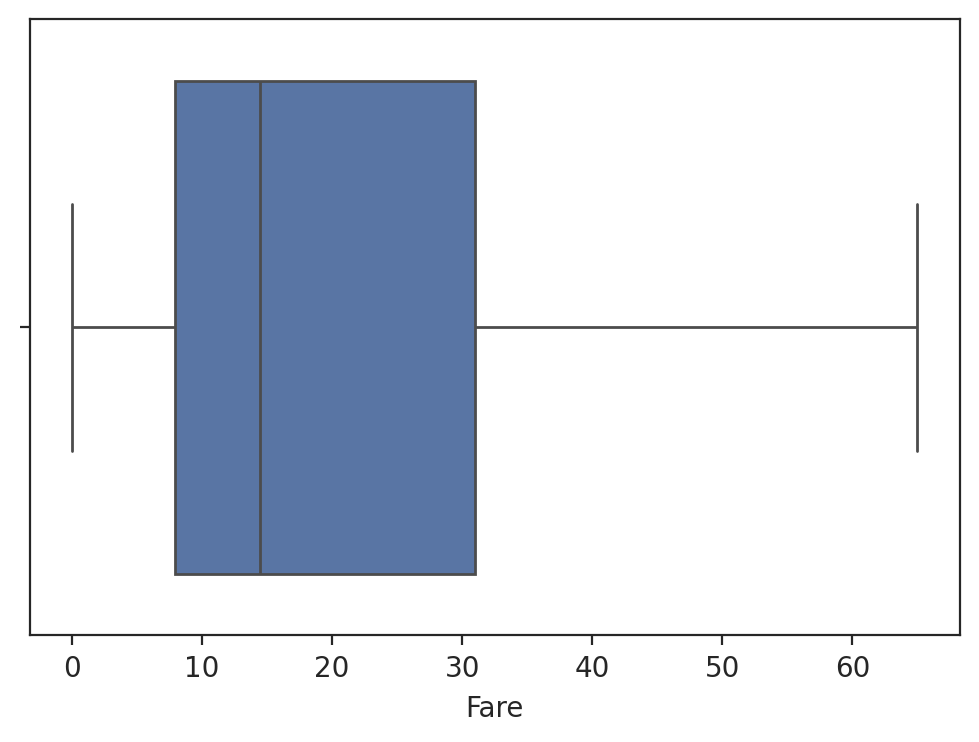

In [19]:
sns.boxplot(data=data, x='Fare', showfliers=False)
plt.show()

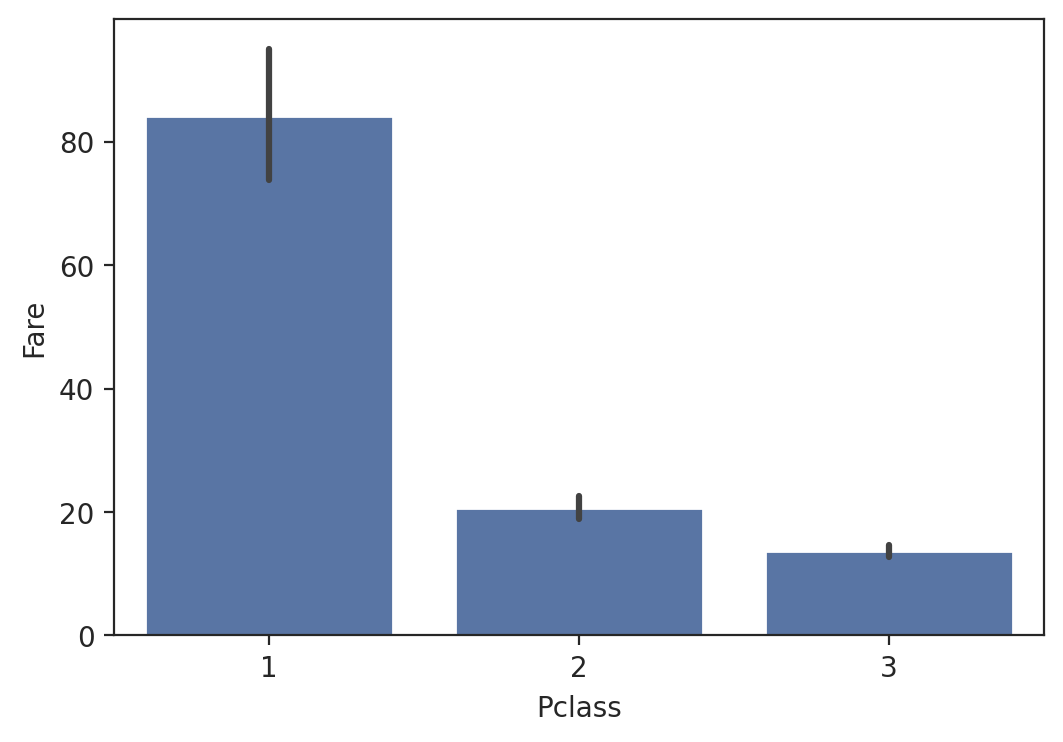

In [20]:
sns.barplot(data=data, x='Pclass', y='Fare')
plt.show()

In [21]:
data.groupby('Pclass')['Fare'].mean()

,Fare
Pclass,
1,84.154687
2,20.662183
3,13.675550


In [22]:
help(data.groupby)

Help on method groupby in module pandas.core.frame:

groupby(
    by=None,
    axis: 'Axis | lib.NoDefault' = <no_default>,
    level: 'IndexLabel | None' = None,
    as_index: 'bool' = True,
    sort: 'bool' = True,
    group_keys: 'bool' = True,
    observed: 'bool | lib.NoDefault' = <no_default>,
    dropna: 'bool' = True
) -> 'DataFrameGroupBy' method of pandas.core.frame.DataFrame instance
    Group DataFrame using a mapper or by a Series of columns.

    A groupby operation involves some combination of splitting the
    object, applying a function, and combining the results. This can be
    used to group large amounts of data and compute operations on these
    groups.

    Parameters
    ----------
    by : mapping, function, label, pd.Grouper or list of such
        Used to determine the groups for the groupby.
        If ``by`` is a function, it's called on each value of the object's
        index. If a dict or Series is passed, the Series or dict VALUES
        will be used t

In [23]:
data.groupby('Pclass')['Fare'].median()

,Fare
Pclass,
1,60.2875
2,14.2500
3,8.0500


### 6.1. Explore survival counts

The next cells count male and female survivors using two equivalent approaches. These are counts, not within-sex survival rates.

In [24]:
data.loc[(data['Sex'] == 'male') & (data['Survived'] == 1), ['Sex']].value_counts()

,count
Sex,
male,109


In [25]:
data.loc[(data['Sex'] == 'female') & (data['Survived'] == 1), ['Sex']].value_counts()

,count
Sex,
female,233


In [26]:
male = ((data['Sex']=='male') & (data['Survived']==1)).sum()
female = ((data['Sex']=='female') & (data['Survived']==1)).sum()
difference = male-female
print(difference)

-124


In [27]:
male = data.loc[(data['Sex']=='male') & (data['Survived']==1), ['Survived']].shape[0]
female = data.loc[(data['Sex']=='female') & (data['Survived']==1), ['Survived']].shape[0]

difference = male - female
print(difference)

-124


#### A note on the next calculation

The next cell is retained from the exploration. `~difference` applies a bitwise inversion to the integer; its output is not a passenger-count difference or a survival measure, so it is not used in the findings.

In [28]:
male = (data['Sex'] == 'male').sum()
female = (data['Sex'] == 'female').sum()
difference = female - male
print(~difference)

262


### 6.2. Compare survival proportions

Review the overall survival percentage, inspect selected records, and compare survival by class and sex. For a binary outcome, the mean represents the survival proportion.

In [29]:
survived = (data['Survived']).value_counts(normalize=True)*100
print(round(survived, 2))

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [30]:
data[data['Pclass']==1]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,C103,S
23,24,1,1,"Sloper, Mr. William Thompson",male,28.0,0,0,113788,35.5000,A6,S
...,...,...,...,...,...,...,...,...,...,...,...,...
871,872,1,1,"Beckwith, Mrs. Richard Leonard (Sallie Monypeny)",female,47.0,1,1,11751,52.5542,D35,S
872,873,0,1,"Carlsson, Mr. Frans Olof",male,33.0,0,0,695,5.0000,B51 B53 B55,S
879,880,1,1,"Potter, Mrs. Thomas Jr (Lily Alexenia Wilson)",female,56.0,0,1,11767,83.1583,C50,C
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S


In [31]:
data.loc[(data['Sex']=='male') & (data['Survived']==0), ['Name']]

,Name
0,"Braund, Mr. Owen Harris"
4,"Allen, Mr. William Henry"
5,"Moran, Mr. James"
6,"McCarthy, Mr. Timothy J"
7,"Palsson, Master. Gosta Leonard"
...,...
881,"Markun, Mr. Johann"
883,"Banfield, Mr. Frederick James"
884,"Sutehall, Mr. Henry Jr"
886,"Montvila, Rev. Juozas"


In [32]:
round(data.groupby('Pclass')['Survived'].mean()*100, 2)

,Survived
Pclass,
1,62.96
2,47.28
3,24.24


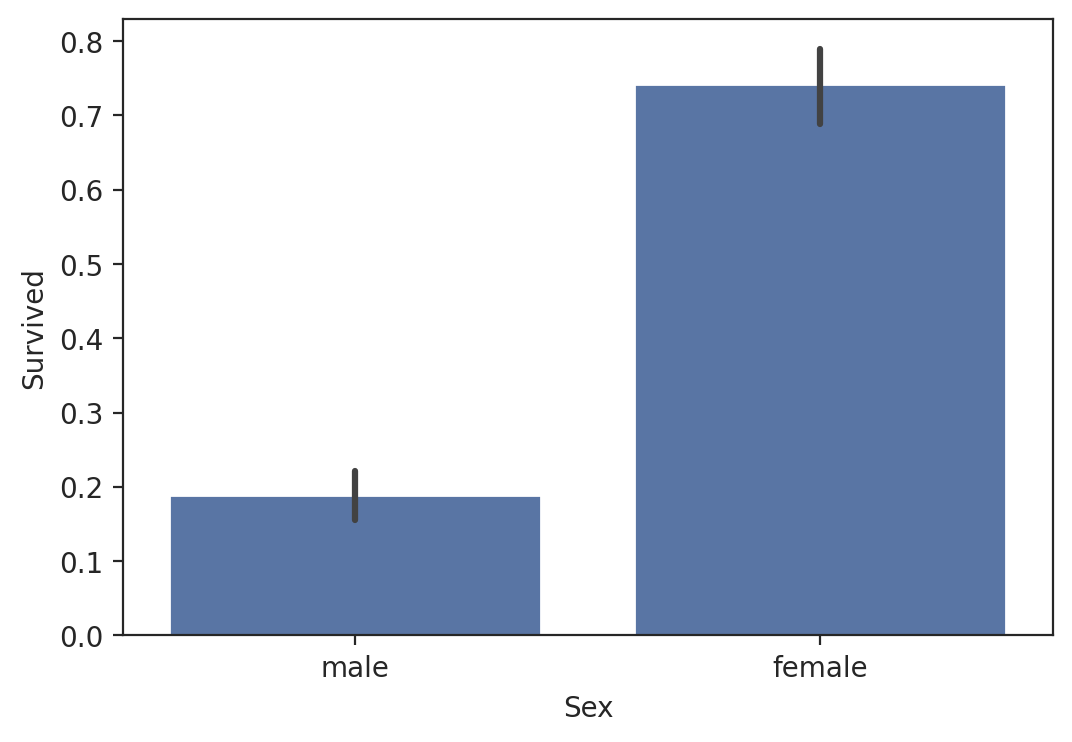

In [33]:
sns.barplot(data=data, x='Sex', y='Survived')
plt.show()

#### Survivor counts versus survival rates

The ratio below compares the number of female survivors with the number of male survivors. It does not account for how many passengers of each sex were aboard, so it should not be interpreted as a ratio of survival probabilities.

In [34]:
m_survived = ((data['Sex']=='male') & (data['Survived']==1)).sum()
f_survived = ((data['Sex']=='female') & (data['Survived']==1)).sum()

f = round(f_survived/m_survived, 2)
m = round(m_survived/f_survived, 2)
print(f" Females survived at a ratio of {f} to males who survived at a ratio of {m}")


 Females survived at a ratio of 2.14 to males who survived at a ratio of 0.47


### 6.3. Look at sex and class together

Compare fares and survival within combinations of class and sex to add context to the age analysis.

In [35]:
data.groupby(['Pclass', 'Sex'])['Fare'].mean()

Pclass  Sex   
1       female    106.125798
        male       67.226127
2       female     21.970121
        male       19.741782
3       female     16.118810
        male       12.661633
Name: Fare, dtype: float64

In [36]:
data.loc[(data['Sex']=='female') & (data['Survived']==1) & (data['Pclass']==3)].shape[0]

72

<Axes: xlabel='Pclass', ylabel='Fare'>

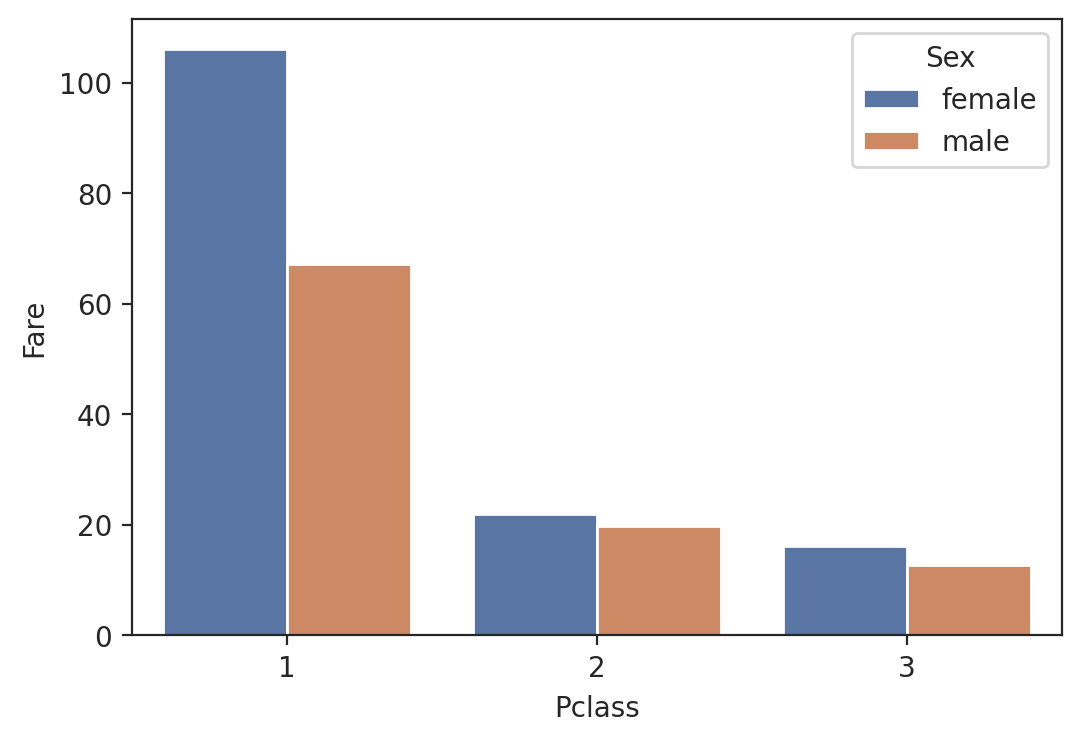

In [37]:
sns.barplot(
    data=data, 
    x='Pclass', 
    y='Fare',
    hue='Sex',
    errorbar=None
)

In [38]:
print(round(data.groupby(['Pclass', 'Sex'])['Survived'].mean()*100, 2))

Pclass  Sex   
1       female    96.81
        male      36.89
2       female    92.11
        male      15.74
3       female    50.00
        male      13.54
Name: Survived, dtype: float64


## 7. Investigate age and survival

### Research question

**Were younger passengers more likely to survive than older passengers?**

I start by checking the available age data, compare the two survival groups, then calculate survival rates within age bands. Rates are useful here because the groups contain different numbers of passengers.

### 7.1. Check age coverage

#### Passengers with a recorded age

In [39]:
rec_age = data[data['Age'].notnull()].shape[0]
print(f"{rec_age} passengers have a recorded age")

714 passengers have a recorded age


#### Passengers with a missing age

In [40]:
missing_age = data[data['Age'].isnull()].shape[0]
print(f"{missing_age} passengers have a missing age")

177 passengers have a missing age


#### Percentage of ages missing

In [41]:
percentage_missing_age = round((data['Age'].isnull()).mean()*100, 2)
print(f"{percentage_missing_age}% of passengers have a missing age")

19.87% of passengers have a missing age


#### How missing ages affect the analysis

There are 714 recorded ages and 177 missing ages (19.87%). Missing ages are already represented as null values. Keeping those rows in `data` preserves them for other comparisons, but does not make their ages usable.

The original comment below is retained. For the age analysis, pandas excludes missing ages from the summaries and leaves their age group unassigned. If passengers with missing ages differed from those with recorded ages, the results could be biased.

In [42]:
#Based on findings i would not exclude passengers with muissing ages, instead i would replace missing valkues with Null values as 80.13% of age data is available and can therefore represent a relioable representation of passengers 

### 7.2. Compare age summaries

#### Mean age by survival outcome

In [43]:
round(data.groupby('Survived')['Age'].mean(), 2)

,Age
Survived,
0,30.63
1,28.34


#### Median age by survival outcome

In [44]:
data.groupby('Survived')['Age'].median()

,Age
Survived,
0,28.0
1,28.0


#### Minimum and maximum ages

Both calculations are retained below. Jupyter normally displays only the final expression in this cell, which is the maximum age.

In [45]:
data.groupby('Survived')['Age'].min()
data.groupby('Survived')['Age'].max()

,Age
Survived,
0,74.0
1,80.0


#### What the summaries suggest

Survivors were younger on average: **28.34 years**, compared with **30.63 years** for non-survivors.

The median age was **28 years in both groups**. This suggests that the difference in mean age does not describe a large shift in the centre of the two distributions.

Averages alone do not show the full distribution. The spread of ages, extreme values and the mix of passengers in each group also matter.

### 7.3. Visualise age and survival

#### Age distributions

The histogram overlays the two survival groups. In the legend, `True` means survived and `False` means did not survive. The bars show passenger counts, rather than survival rates.

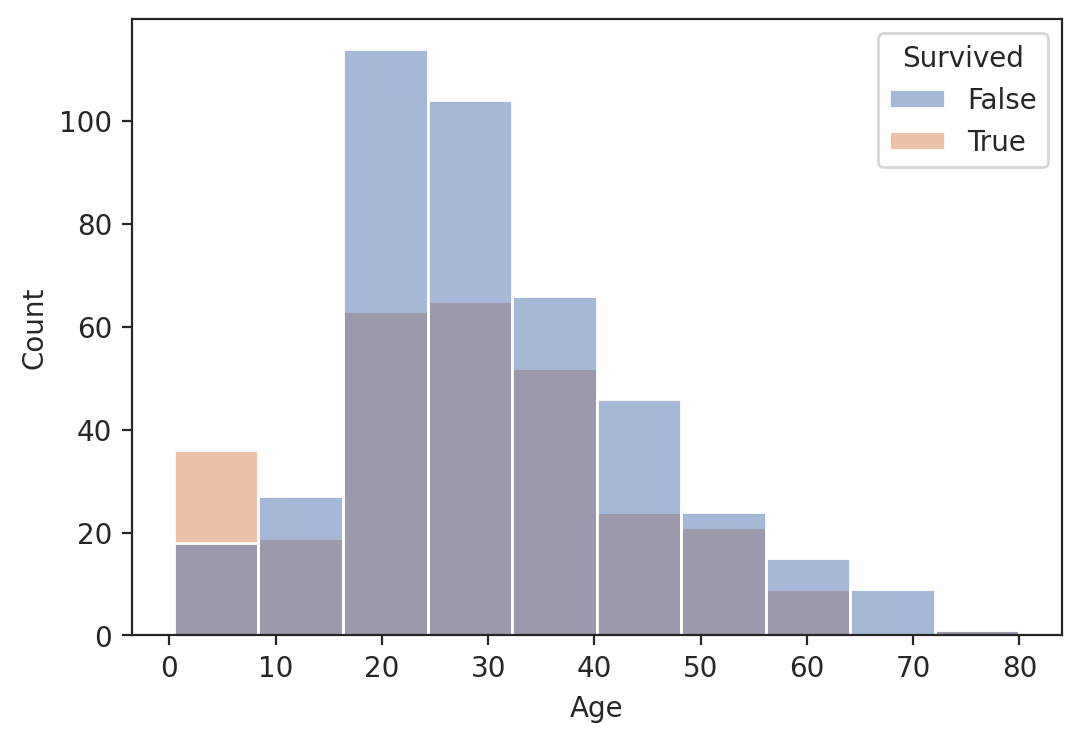

In [46]:
sns.histplot(
    data=data,
     x='Age',
    hue=(data['Survived']==1),
    bins=10
    )
plt.show()

#### Age spread by survival outcome

Compare ages for non-survivors (`0`) and survivors (`1`). Outlier markers are hidden in this chart.

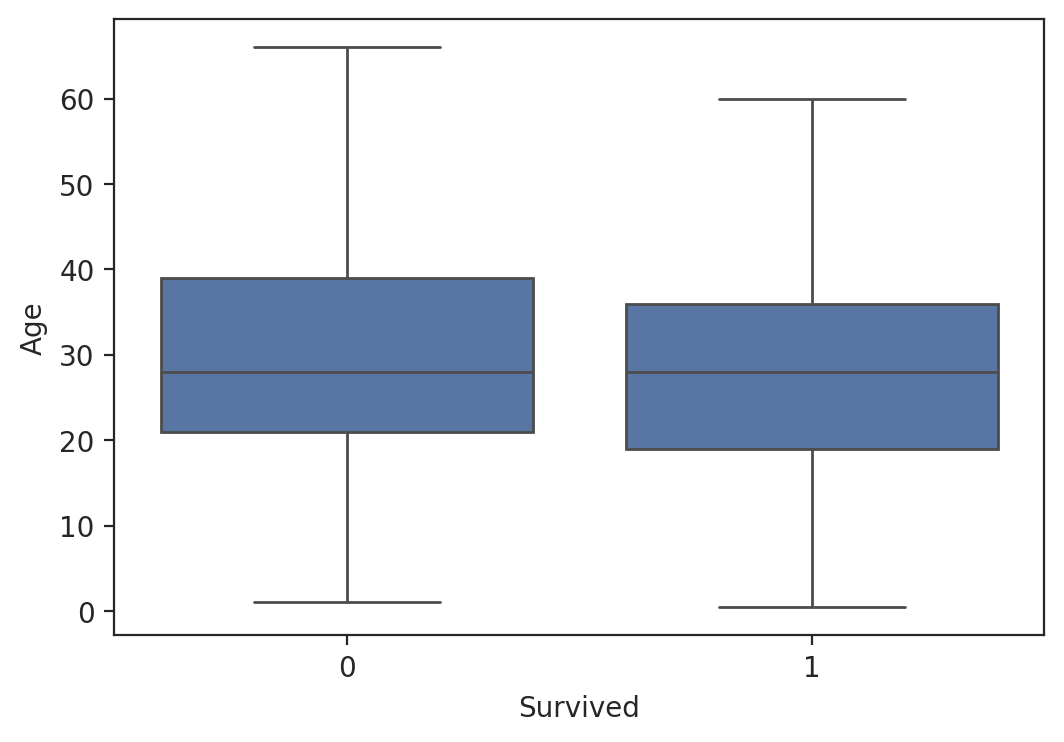

In [47]:
sns.boxplot(
    data=data, 
    x='Survived',
    y='Age',  
    showfliers=False
    )
plt.show()

#### Reading the charts

Most recorded ages appear concentrated around **18–40 years**, based on the histogram.

The two distributions overlap substantially. The charts do not suggest a simple separation between younger survivors and older non-survivors.

The boxplots show broadly similar age spreads, consistent with the identical median ages.

Raw counts can be misleading because age groups contain different numbers of passengers. A group can have more survivors simply because it has more passengers. Comparing the proportion who survived within each group addresses that issue.

### 7.4. Compare survival rates across age groups

#### Create age groups

Group passengers by their recorded age to make the survival comparison easier to read.

The code uses the following intervals. These match `pd.cut` exactly, including how fractional ages are assigned.

| Group | Recorded age interval |
| --- | --- |
| Children | 0 to 12, inclusive |
| Teenagers | Over 12 to 17, inclusive |
| Young adults | Over 17 to 35, inclusive |
| Middle-aged adults | Over 35 to 59, inclusive |
| Older adults | Over 59 |

Missing ages remain unassigned. The ten-row sample can change each time the cell runs because no random seed is set.

In [48]:
bins = [0,12,17,35,59, np.inf]
lab = ['Children', 'Teenagers', 'Young Adults', 'Middle-aged Adults', 'Older adults']

data['AgeGroup'] = pd.cut(data['Age'], bins=bins, labels=lab, include_lowest=True)

data[['Age','AgeGroup']].sample(10)

,Age,AgeGroup
117,29.0,Young Adults
586,47.0,Middle-aged Adults
291,19.0,Young Adults
446,13.0,Teenagers
179,36.0,Middle-aged Adults
658,23.0,Young Adults
721,17.0,Teenagers
152,55.5,Middle-aged Adults
852,9.0,Children
244,30.0,Young Adults


#### Calculate survival rates

Because `Survived` is coded as 0 or 1, its group mean is the proportion who survived. Multiplying by 100 gives a percentage.

In [49]:
round(data.groupby('AgeGroup')['Survived'].mean()*100, 2)

,Survived
AgeGroup,
Children,57.97
Teenagers,47.73
Young Adults,38.02
Middle-aged Adults,39.79
Older adults,26.92


#### Plot survival by age group

The bar heights show survival proportions on a 0–1 scale: 0.5 represents 50%.

<Axes: xlabel='AgeGroup', ylabel='Survived'>

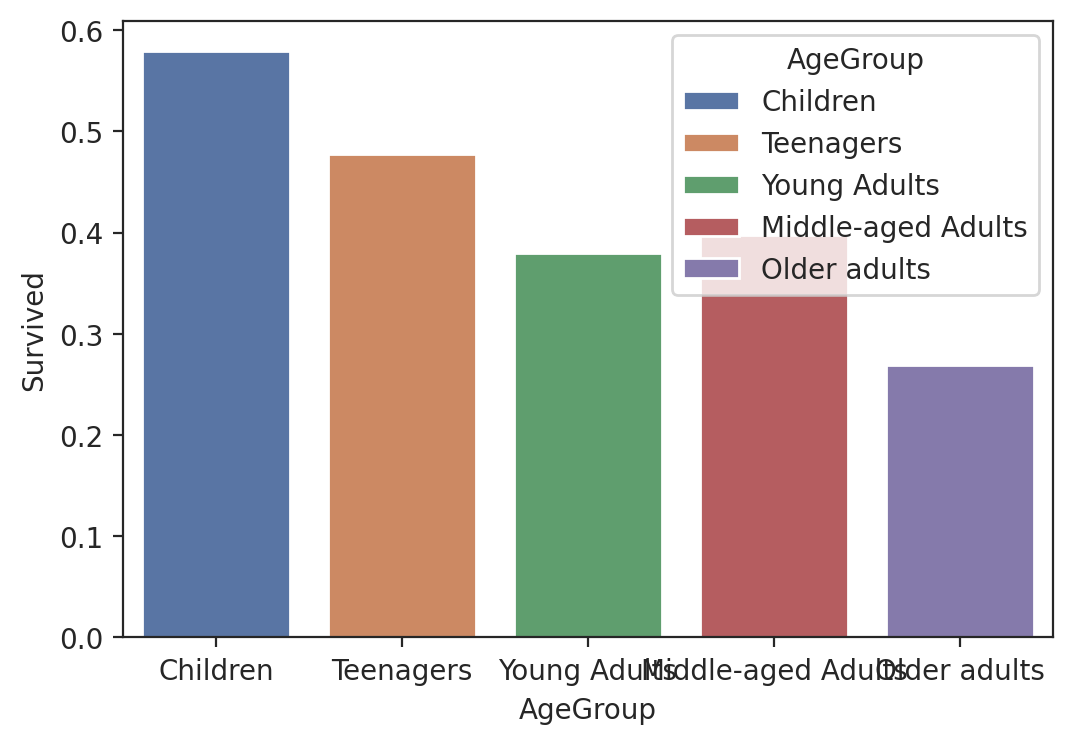

In [50]:
sns.barplot(
    data=data,
    hue='AgeGroup',
    y='Survived',
    x='AgeGroup',
    errorbar=None,
)

#### What the age groups show

**Children had the highest survival rate: 57.97%** among 69 passengers with recorded ages in that group.

**Older adults had the lowest survival rate: 26.92%** among 26 passengers. This smaller group makes its rate more sensitive to individual outcomes.

Survival generally fell across the age groups, but the pattern was not consistent. Middle-aged adults had a slightly higher survival rate (**39.79%**) than young adults (**38.02%**).

Changing the age boundaries could change the rates and even the ordering of groups, especially where there are few passengers. Checking alternative boundaries would help assess how stable the pattern is.

## 8. Findings, limitations and next steps

### Answering the research question

The results suggest an association between age and survival, with children having the highest survival rate in this dataset. Among passengers with recorded ages, 57.97% of children survived, compared with 26.92% of older adults. Survivors were also younger on average: 28.34 years versus 30.63 years for non-survivors. However, both groups had a median age of 28 years, and their age distributions overlapped substantially. The age-group pattern was not a steady decline either: middle-aged adults had a slightly higher survival rate than young adults. Taken together, these findings suggest that children had a survival advantage in these records, but age alone does not explain survival. Sex, passenger class and missing age information need to be considered before drawing stronger conclusions.

### Other factors to consider

Passenger class and sex were also associated with survival in the earlier comparisons. First-class passengers had a survival rate of 62.96%, compared with 24.24% in third class. If the age groups contain different mixes of classes and sexes, some of the apparent age relationship may reflect those differences.

### Limitations

- **Missing age data:** 19.87% of passengers have no recorded age. The age analysis cannot represent them directly, and their missingness may not be random.
- **Group boundaries and sample size:** Age bands simplify the data and depend on chosen cut-offs. The older-adult group contains only 26 passengers.
- **Unadjusted comparisons:** These descriptive comparisons do not separate age from class, sex or other factors. They show associations, not causal effects.

### Further investigation

A useful next step would be to compare age-specific survival rates within each sex and passenger class. A logistic regression could then assess whether age remains associated with survival after accounting for those variables. Trying alternative age bands and approaches to missing ages would help check whether the conclusions are stable.

These are proposed next steps; no predictive model is fitted in this notebook.